# Интеллектуальная система оценки для «AutoValue AI»<a id='start'></a>
- Автор: Якунина Анна
- Дата: 18.08.2026
- https://github.com/Nancy-Vad/AutoAI

## Цели и задачи проекта
### Цель проекта -  построить ML-модель автоматизированной системы оценки цены на автомобиль.
 ### Задачи проекта
1. Провести **EDA** (экспресс-анализ данных).
3. Предобработать данные для честного соревнования библиотек.
4. Обучить модели в разных библиотеках: **XGBoost, CatBoost и LightGBM**.
5. Подобрать лучшие гиперпараметры с Optuna.
6. Проанализировать Топ-5 признаков.
7. Сравнить модели по метрикам регрессии и бизнес-метрикам.
8. Выявить марки машин и регионы, где риск ошибки высок.
9. Проверить модель на тестовой выборке.
10. Подготовить артефакты модели для внедрения.
11. Подготовить аналитическую записку по проекту.

## Описание данных
`ds_s16_train_data.csv` - датасет для обучения и валидации модели  
`ds_s16_test_data.csv` - датасет для финальной проверки модели и итоговой оценки её качества

Датасет `ds_s16_train_data.csv` - тренировочная выборка, содержит историю 8 000 сделок.
Датасет `ds_s16_test_data.csv` — тестовая выборка (2 000 записей).
 
- `brand` - Марка автомобиля. Фундамент цены: престиж и надёжность бренда.
- `make_year` -	Год выпуска. Главный счётчик амортизации: чем старше автомобиль, тем дешевле.
- `mileage_kmpl` - Топливная эффективность транспортного средства, которая показывает, сколько километров автомобиль может проехать на одном литре топлива.
- `engine_cc` -	Объём двигателя (в кубических см). Влияет на мощность, налоги и интерес покупателей.
- `fuel_type` - Тип топлива. Экономичность против мощности. Важный фактор ликвидности.
- `transmission` - Тип коробки передач.	«Автомат» или «механика» — ключевой фактор комфорта.
- `owner_count`	- Количество владельцев по ПТС.	Юридическая чистота и аккуратность эксплуатации.
- `color` - Цвет автомобиля.	Психологический фактор: популярные цвета продаются быстрее.
- `service_history` - Наличие сервисной книжки.	Подтверждает, что за машиной ухаживали вовремя.
- `accidents_reported` - Количество зафиксированных ДТП. Сильно бьёт по цене и безопасности будущей сделки.
- `insurance_valid`	- Действительна ли страховка. Снижает первичные расходы покупателя после сделки.
- `region` - Макрорегион РФ, в котором продаётся автомобиль (Москва, Сибирь, Юг). Позволяет модели учитывать региональную специфику цен.
- `price_rub` - Целевой признак: рыночная стоимость автомобиля в рублях	Реальная сумма сделки, которую нужно предсказать.

## Содержимое проекта
1. [Постановка задачи машинного обучения](#task)
2. [Подключение и настройка библиотек](#libs)
3. [Константы/Config](#config)
4. [Загрузка данных](#upload)
5. [Исследовательский анализ данных](#research)
7. [Разделение данных на выборки](#sample)
9. [Обучение моделей в разных библиотеках](#train)
10. [Подбор гиперпараметров с Optuna](#optuna)
11. [Интерпретация и бизнес-анализ](#analysis)
12. [Финальная модель](#final)
13. [Аналитическая записка по проекту AutoValue AI](#resume)

---
## 1. Постановка задачи машинного обучения <a id = 'task'></a>
- **Тип задачи** - задача регрессии:
построить модель ценообразования, которая по характеристикам подержанного автомобиля прогнозирует его рыночную стоимость (price_rub) для принятия решения о закупке.
- **Целевая переменная**:
    - `price_rub` - непрерывная величина, рыночная стоимость автомобиля в рублях.
- **Ключевые метрики качества модели**:
    - **RMSE**, **MAE**, **R2** - стандартные метрики качества регрессии;
    - **Overpricing Rate** (доля опасных переплат) - процент случаев, когда модель предсказала цену на 20% выше реальной;
    - **Underpricing Loss** (упущенная выгода): суммарная разница в случаях, когда модель занизила цену более чем на 20%.
- **Технические требования к реализации**
    - **Библиотеки-участники турнира:**
        - XGBoost;
        - LightGBM;
        - CatBoost.
    - **Итоговая модель:**
        - лучшая по совокупности регрессионных и бизнес-метрик библиотека с оптимальными гиперпараметрами, подобранными через Optuna.
    - **Воспроизводимость:**
        - фиксированный random_state = 42 во всех моделях;
        - единый train/val сплит (80/20), одинаковый для всех трёх библиотек;
        - фиксированный отложенный тест (`ds_s16_test_data.csv`), не используемый на этапах обучения и подбора гиперпараметров.
    - **Валидация:**
        - hold-out валидация (80/20) на этапе сравнения моделей и тюнинга;
        - финальная проверка — на отложенной тестовой выборке (2000 записей), без какого-либо участия в обучении/подборе параметров.
    - **Интерпретируемость:**
        - SHAP-анализ важности признаков для топ-3 моделей;
        - разбивка бизнес-метрик (Overpricing Rate, Underpricing Loss) по маркам (brand) и регионам (region) для выявления систематических перекосов модели.
- **Подготовка к внедрению:**
    - сохранение итоговой модели-победителя турнира для дальнейшего использования в промышленной эксплуатации.

---
## 2. Подключение и настройка библиотек <a id = 'libs'></a>

- Загружаем необходимые библиотеки Python

In [1]:
#%pip install -r requirements.txt

In [2]:
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna 
import seaborn as sns
import shap
import lightgbm as lgb

from time import time, perf_counter
from phik import phik_matrix

from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn import set_config

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

---
## 3. Константы/Config <a id='config'></a>

In [5]:
RANDOM_STATE = 42
VAL_SHARE = 0.2

pd.set_option('display.max_columns', None)
pd.set_option('display.max_seq_items', 5)
np.set_printoptions(threshold=10) 
set_config(transform_output="pandas")
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 4. Загрузка данных <a id = 'upload'></a>
### 4.1. Загрузка датасетов

In [6]:
filenames = ['ds_s16_train_data.csv', 'ds_s16_test_data.csv']

In [7]:
# Функция для загрузки файлов 
def load_dataset(filename):
    local_paths = [f'/datasets/{filename}', f'datasets/{filename}']
    for local_path in local_paths:
        try:
            df = pd.read_csv(local_path)
            print(f'Файл успешно загружен из локального хранилища: {local_path}')
            return df
        
        except FileNotFoundError:
            continue
            
    print(f'Локальный файл {filename} не найден. Пробуем скачать из внешнего хранилища...')
        
    url = f'https://code.s3.yandex.net/datasets/{filename}'
    try:
        df = pd.read_csv(url)            
        print(f'Файл успешно скачан по ссылке: {url}')
        return df
    
    except Exception as e:
        print(f'Произошла неизвестная ошибка: {str(e)}')
        return None

- Загрузим данные датасетов

In [8]:
df_dict = {}

for filename in filenames:
    df = load_dataset(filename)
    df_dict[filename] = df

Файл успешно загружен из локального хранилища: datasets/ds_s16_train_data.csv
Файл успешно загружен из локального хранилища: datasets/ds_s16_test_data.csv


---
### 4.2. Знакомство с данными
#### 4.2.1. Датасет `ds_s16_train_data.csv`

- Знакомимся с данными датасета `ds_s16_train_data.csv`

In [9]:
df_train = df_dict['ds_s16_train_data.csv']
df_train.head(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2002,9.70,1800,Diesel,2,Hyundai,Manual,Silver,Partial,0,No,242073,Урал
1,2004,16.10,1500,Diesel,3,Hyundai,Manual,Black,Unknown,0,No,426029,Москва
2,2005,10.51,5000,Diesel,2,Ford,Manual,Gray,Full,0,No,727050,Юг
3,2019,14.27,2000,Petrol,5,Hyundai,Manual,White,Full,1,Yes,753168,Дальний Восток
4,2015,21.72,1000,Petrol,1,Toyota,Automatic,Black,Full,0,Yes,733390,Сибирь


In [10]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           8000 non-null   int64  
 1   mileage_kmpl        8000 non-null   float64
 2   engine_cc           8000 non-null   int64  
 3   fuel_type           8000 non-null   object 
 4   owner_count         8000 non-null   int64  
 5   brand               8000 non-null   object 
 6   transmission        8000 non-null   object 
 7   color               8000 non-null   object 
 8   service_history     8000 non-null   object 
 9   accidents_reported  8000 non-null   int64  
 10  insurance_valid     8000 non-null   object 
 11  price_rub           8000 non-null   int64  
 12  region              8000 non-null   object 
dtypes: float64(1), int64(5), object(7)
memory usage: 812.6+ KB


#### Выводы
Датасет `ds_s16_train_data.csv` содержит **8000 строк и 13 столбцов**:
- **7 столбцов** - тип `object`;
- **5 столбцов** - тип `int64`;
- **1 столбцов** - тип `float64`.
- **Пропуски в датасете отсутствуют**.
-  Столбцы с типом `object` следует привести к типу `category`.

---
#### 4.2.1. Датасет `ds_s16_test_data.csv`

- Знакомимся с данными датасета `ds_s16_test_data.csv`

In [11]:
df_test = df_dict['ds_s16_test_data.csv']
df_test.head(5)

,make_year,mileage_kmpl,engine_cc,fuel_type,owner_count,brand,transmission,color,service_history,accidents_reported,insurance_valid,price_rub,region
0,2015,12.09,5000,Diesel,1,Nissan,Automatic,White,Full,2,No,1213351,Москва
1,2016,14.03,800,Petrol,4,Chevrolet,Manual,White,Partial,0,Yes,586881,Дальний Восток
2,2005,20.40,2000,Petrol,1,Kia,Manual,Blue,Full,2,Yes,650752,Сибирь
3,1996,25.09,800,Diesel,3,Volkswagen,Manual,Silver,Full,0,Yes,320452,Урал
4,1995,19.25,5000,Diesel,5,Hyundai,Automatic,Black,Partial,0,No,694911,СПб


In [12]:
df_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   make_year           2000 non-null   int64  
 1   mileage_kmpl        2000 non-null   float64
 2   engine_cc           2000 non-null   int64  
 3   fuel_type           2000 non-null   object 
 4   owner_count         2000 non-null   int64  
 5   brand               2000 non-null   object 
 6   transmission        2000 non-null   object 
 7   color               2000 non-null   object 
 8   service_history     2000 non-null   object 
 9   accidents_reported  2000 non-null   int64  
 10  insurance_valid     2000 non-null   object 
 11  price_rub           2000 non-null   int64  
 12  region              2000 non-null   object 
dtypes: float64(1), int64(5), object(7)
memory usage: 203.3+ KB


#### Выводы
Датасет `ds_s16_test_data.csv` содержит **2000 строк и 13 столбцов**:
- **7 столбцов** - тип `object`;
- **5 столбцов** - тип `int64`;
- **1 столбцов** - тип `float64`.
- **Пропуски в датасете отсутствуют**.
- -  Столбцы с типом `object` следует привести к типу `category`.

---
### 4.3. Приведение типов данных

- Приведем категориальные признаки датасетов `ds_s16_train_data.csv` и `ds_s16_test_data.csv` к типу `category`

In [13]:
cat_features = df_train.select_dtypes(include='object').columns.tolist()
    
for cat in cat_features:
    df_train[cat] = df_train[cat].astype('category')
    df_test[cat] = df_test[cat].astype('category')

print('*' * 50)
print('Тренировочный датасет:')
print('*' * 50)
print(df_train.info())
print('*' * 50)
print('Тестовый датасет:')
print('*' * 50)
print(df_test.info())

**************************************************
Тренировочный датасет:
**************************************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   make_year           8000 non-null   int64   
 1   mileage_kmpl        8000 non-null   float64 
 2   engine_cc           8000 non-null   int64   
 3   fuel_type           8000 non-null   category
 4   owner_count         8000 non-null   int64   
 5   brand               8000 non-null   category
 6   transmission        8000 non-null   category
 7   color               8000 non-null   category
 8   service_history     8000 non-null   category
 9   accidents_reported  8000 non-null   int64   
 10  insurance_valid     8000 non-null   category
 11  price_rub           8000 non-null   int64   
 12  region              8000 non-null   category
dtypes: category(7

In [14]:
cat_features = df_train.select_dtypes(include='category').columns.tolist()
cat_features

['fuel_type',
 'brand',
 'transmission',
 'color',
 'service_history',
 'insurance_valid',
 'region']

---
## 5. Исследовательский анализ данных <a id = 'research'></a>
### 5.1. Анализ целевой переменной

- Изучим распределение значений по столбцу - `price_rub`

In [15]:
round(df_train['price_rub'].describe(),2)

count       8000.00
mean      683647.87
std       264923.50
min        95000.00
25%       493857.00
50%       663866.00
75%       855056.00
max      1676525.00
Name: price_rub, dtype: float64

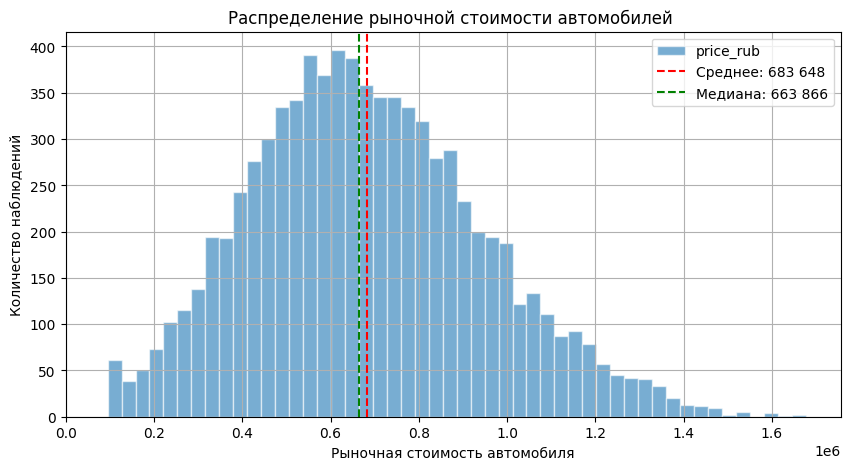

In [16]:
plt.figure(figsize=(10, 5))

df_train['price_rub'].plot(
    kind='hist',
    grid=True,
    alpha=0.6,
    edgecolor='white',
    bins=50
)

plt.axvline(df_train['price_rub'].mean(), color='red', linestyle='--', label=f"Среднее: {df_train['price_rub'].mean():,.0f}".replace(',', ' '))
plt.axvline(df_train['price_rub'].median(), color='green', linestyle='--', label=f"Медиана: {df_train['price_rub'].median():,.0f}".replace(',', ' '))

plt.title(f'Распределение рыночной стоимости автомобилей ')
plt.xlabel('Рыночная стоимость автомобиля')
plt.ylabel('Количество наблюдений')
plt.xlim(left=0)
plt.legend()

plt.show()

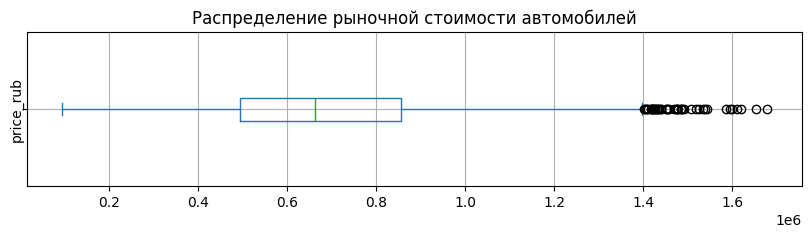

In [17]:
df_train['price_rub'].plot(
    kind='box',
    figsize=(10, 2),
    showfliers=True,
    vert=False,
    grid=True
)

plt.title('Распределение рыночной стоимости автомобилей')
plt.yticks(rotation=90)
plt.setp(plt.gca().get_yticklabels(), va='center', ha='center')

plt.show()

#### Выводы
- Распределение целевой переменной `price_rub` **близко к нормальному**, но с небольшой правой асимметрией.
- Среднее (683 648) чуть выше медианы (663 866) — типичная картина для цен: основная масса машин группируется в среднем ценовом сегменте, но есть "хвост" из более дорогих авто.
- Присутствует немного **реальных выбросов** — все они на верхнем конце (машины дороже ~1.4 млн).
- Реальных отрицательных цен нет — **минимум составляет 95 000 руб.**.
- **Диапазон цен достаточно широкий** (95тыс–1.68 млн, разброс почти в 18 раз) — от бюджетных до премиальных авто, что соответствует наличию в данных как массовых брендов (Hyundai, Kia), так и премиальных (BMW, Tesla).

---
### 5.2. Корреляция

- Рассчитаем коэффициент корреляции **phi_k** между признаками и целевой переменной `price_rub`	

In [18]:
ph_matrix = df_train.phik_matrix()
ph_target = ph_matrix.loc[ph_matrix.index != 'price_rub'][['price_rub']].sort_values(by='price_rub', ascending=False)

interval columns not set, guessing: ['make_year', 'mileage_kmpl', 'engine_cc', 'owner_count', 'accidents_reported', 'price_rub']


- Визуализируем тепловую карту коэффициента **phi_k** для целевой переменной

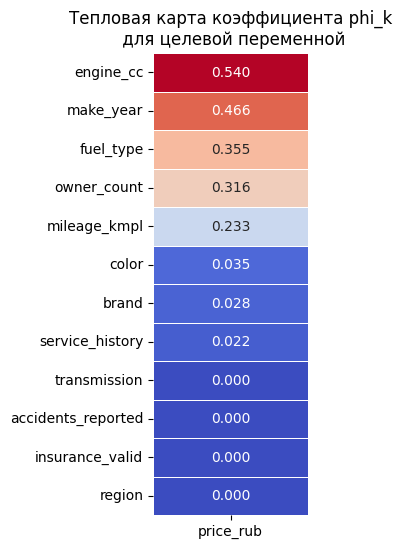

In [19]:
plt.figure(figsize=(2, 6))

sns.heatmap(
    ph_target,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar=False
)

plt.title('Тепловая карта коэффициента phi_k\n для целевой переменной')

plt.show()

#### Выводы
- `engine_cc` (0.54) — безусловный **лидер**:
    - объём двигателя явно главный ценообразующий фактор;
    - одновременно отражает и мощность, и класс/сегмент автомобиля.
- `make_year` (0.47) — **второй по значимости**:
    - чем новее машина, тем дороже.
- `fuel_type` (0.35) — **неожиданно высокая позиция**:
    - возможно, категория Electric, которая сильно выделяется по цене (электромобили часто дороже) "тянут" метрику вверх.
- `owner_count` (0.32) и `mileage_kmpl` (0.23) - **умеренная связь**:
    - больше владельцев и пробег - ниже цена.
- `color`, `brand`, `service_history` — **очень слабая связь** (0.02–0.04).
- `transmission`, `accidents_reported`, `insurance_valid`, `region` - **ровно 0.00**.

---
## 6. Разделение данных на выборки <a id='sample'></a>

-  Разделим данные на **train и val** в соотношении **80/20**
-  Подготовим **test**

In [20]:
X = df_train.drop(columns=['price_rub'])
y = df_train['price_rub']

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=VAL_SHARE, random_state=42
)

X_test = df_test.drop(columns=['price_rub'])
y_test = df_test['price_rub']

print('\nРазмеры выборок:')
print('*' * 55)
print(f'train: {X_train.shape} {y_train.shape}')
print(f'val: {X_val.shape} {y_val.shape}')
print(f'test: {X_test.shape} {y_test.shape}')


Размеры выборок:
*******************************************************
train: (6400, 12) (6400,)
val: (1600, 12) (1600,)
test: (2000, 12) (2000,)


---
## 7. Обучение моделей в разных библиотеках <a id='train'></a>
### 7.1. Обучение базовых моделей

- Создадим три модели: **XGBoost, CatBoost и LightGBM**

In [21]:
xgb = XGBRegressor(
    objective='reg:absoluteerror',
    eval_metric='mae',
    random_state=RANDOM_STATE,
    enable_categorical=True
)
lgbm = LGBMRegressor(
    objective='mae',
    metric='mae',
    random_state=RANDOM_STATE,
    verbosity=1
)
catboost = CatBoostRegressor(
    loss_function='MAE',
    eval_metric='MAE',
    random_state=RANDOM_STATE, 
    cat_features=cat_features
)
models = {
    'XGBoost': xgb,
    'LightGBM': lgbm,
    'CatBoost': catboost
}

- Реализуем функции для расчета метрик

In [22]:
def regression_metrics(y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    return rmse, mae, r2
    
def business_metrics(y_true, y_pred):
    error_ratio = (y_pred - y_true) / y_true
    
    overpricing_rate = (error_ratio > 0.20).mean()
    
    under_mask = error_ratio < -0.20
    underpricing_loss = (y_true[under_mask] - y_pred[under_mask]).sum()

    return overpricing_rate, underpricing_loss

def evaluate(model_name, y_true, y_pred):
    rmse, mae, r2 = regression_metrics(y_true, y_pred)
    overpricing_rate, underpricing_loss = business_metrics(y_true, y_pred)
    
    row = {'Модель': model_name, 
           'RMSE': rmse, 
           'MAE': mae, 
           'R2': r2, 
           'Overpricing Rate': overpricing_rate, 
           'Underpricing Loss': underpricing_loss
          }

    return row

- Обучим модели и рассчитаем метрики

In [23]:
results = []
for name, model in models.items():
    start = perf_counter()
    print('*' * 50)
    print(f'Обучение {name}')
    print('*' * 50)
    if model == xgb:
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=10)
    elif model == lgbm:
         model.fit(X_train, y_train, eval_set=[(X_val, y_val)], categorical_feature=cat_features, callbacks=[lgb.log_evaluation(period=10)])
    else:
        model.fit(X_train, y_train, eval_set=(X_val, y_val), verbose=100)
    duration_fit = perf_counter() - start
    
    start = perf_counter()
    y_pred = model.predict(X_val)
    duration_predict = perf_counter() - start
    
    row = evaluate(name, y_val, y_pred)
    row['Время обучения'] = duration_fit
    row['Время предсказания'] = duration_predict
    
    results.append(row)

**************************************************
Обучение XGBoost
**************************************************
[0]	validation_0-mae:163657.78781
[10]	validation_0-mae:85495.62920
[20]	validation_0-mae:84644.78131
[30]	validation_0-mae:84648.30233
[40]	validation_0-mae:85023.30474
[50]	validation_0-mae:85180.53130
[60]	validation_0-mae:85347.24319
[70]	validation_0-mae:85465.45343
[80]	validation_0-mae:85441.20990
[90]	validation_0-mae:85441.19585
[99]	validation_0-mae:85486.96540
**************************************************
Обучение LightGBM
**************************************************
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000411 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 347
[LightGBM] [Info] Number of data points in the train set: 6400, number of used features: 12
[LightGBM] [Info] Start training fro

In [24]:
pd.DataFrame(results).style.format({
    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R2': '{:.3f}',
    'Overpricing Rate': '{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Время обучения': '{:.3f}',
    'Время предсказания':  '{:.3f}'
})

,Модель,RMSE,MAE,R2,Overpricing Rate,Underpricing Loss,Время обучения,Время предсказания
0,XGBoost,107 963,85 487,0.828,14.44%,23 654 384,0.421,0.012
1,LightGBM,102 804,81 979,0.844,13.94%,19 556 105,8.569,0.010
2,CatBoost,99 022,79 343,0.855,13.38%,16 566 048,28.814,0.006


#### Выводы
- **CatBoost**:
    - лидирует по метрикам регрессии (RMSE/MAE/R2) и по обеим бизнес-метрикам;
    - максимальное время обучения;
    - минимальное время инференса.
- **LightGBM**:
    - на втором месте по метрикам бизнеса и регрессии, довольно близко к CatBoost, разрыв заметно меньше, чем у XGBoost;
    - минимальное время обучения;
    - время инференса - 2-ое место;
- **XGBoost**:
    - на последнем месте по метрикам регрессии и бизнес-метрикам;
    - время обучения - 2-ое место;
    - максимальное время инференса.

**Гипотеза:** 
- если не планируется **часто** переобучать модель в проде - **CatBoost** предпочтительнее за счёт **прямой экономии на бизнес-метриках**, которая в масштабе превысит разовые вычислительные издержки.

---
### 7.2. Модель CatBoost с использованием Quantile Loss

- Обучим базовую модель с функцией потерь MAE и рассчитаем метрики

In [25]:
results = []
model_base = CatBoostRegressor(
    loss_function='MAE',
    random_state=RANDOM_STATE,
    cat_features=cat_features,
    verbose=False
)
    
model_base.fit(X_train, y_train)
y_pred = model_base.predict(X_val)
    
row = evaluate('Baseline (MAE)', y_val, y_pred)
    
results.append(row)

- Обучим модель с использованием Quantile Loss и рассчитаем метрики

In [26]:
alphas = [0.5, 0.45, 0.40, 0.35, 0.30, 0.25, 0.20]

for alpha in alphas:
    model = CatBoostRegressor(
        loss_function=f'Quantile:alpha={alpha}',
        random_state=RANDOM_STATE,
        cat_features=cat_features,
        verbose=False
    )
    
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    
    row = evaluate(f'Quantile:alpha={alpha}', y_val, y_pred)
    
    results.append(row)

In [27]:
results_df = pd.DataFrame(results)

base_over = results_df.iloc[0, 4]
base_under = results_df.iloc[0, 5]

results_df['Изменение OR'] = (results_df['Overpricing Rate'] - base_over) / base_over
results_df['Изменение UL'] = (results_df['Underpricing Loss'] - base_under) / base_under

In [28]:
results_df[['Модель', 'RMSE', 'MAE', 'R2', 'Overpricing Rate', 'Изменение OR', 'Underpricing Loss', 'Изменение UL']] \
.style.format({
    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R2': '{:.3f}',
    'Overpricing Rate': '{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Изменение OR': '{:+.2%}',
    'Изменение UL': '{:+.2%}'
})

,Модель,RMSE,MAE,R2,Overpricing Rate,Изменение OR,Underpricing Loss,Изменение UL
0,Baseline (MAE),99 047,79 367,0.855,13.38%,+0.00%,16 699 542,+0.00%
1,Quantile:alpha=0.5,99 047,79 367,0.855,13.38%,+0.00%,16 699 542,+0.00%
2,Quantile:alpha=0.45,100 426,80 446,0.851,12.31%,-7.94%,22 840 978,+36.78%
3,Quantile:alpha=0.4,102 805,82 553,0.844,10.69%,-20.09%,29 786 377,+78.37%
4,Quantile:alpha=0.35,106 066,85 339,0.834,9.06%,-32.24%,36 412 656,+118.05%
5,Quantile:alpha=0.3,110 974,89 369,0.818,8.12%,-39.25%,45 497 557,+172.45%
6,Quantile:alpha=0.25,117 532,95 128,0.796,6.50%,-51.40%,61 239 457,+266.71%
7,Quantile:alpha=0.2,126 622,103 259,0.763,5.06%,-62.15%,81 099 299,+385.64%


#### Выводы
**Оптимальное значение: alpha = 0.40**
- **Overpricing Rate** снижается почти на треть (с 13.4% до 10.7%);
- рост **Underpricing Loss** (+78%) ещё находится в области приемлемых значений.

**Рекомендации**
- **Если приоритет - не потерять деньги** на конкретной неудачной покупке (одна переплаченная машина = прямой видимый убыток при перепродаже) — квантильная модель оправдана: количество "опасных" сделок снижается почти на треть.
- Но **упущенная выгода растёт быстрее**, чем падает риск переплаты (+78% против -20%) — то есть в чистых деньгах quantile-модель обходится компании дороже: рост Underpricing Loss (13.1 млн) кратно превышает "сэкономленные" от снижения Overpricing суммы.
- Можно **предложить гибридный подход**, а не полную замену — использовать quantile-модель только для дорогих/премиальных сделок (где переплата особенно болезненна, например BMW), а для основной массы сделок оставить базовую модель.

---
## 8. Подбор гиперпараметров с Optuna <a id='optuna'></a>
### 8.1. Функция цели для Optuna

- Определим функцию-цель и настроим диапазоны гиперпараметров

In [29]:
def objective(trial, mod='catboost'):
    if mod == 'xgb':
        params = {
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
            'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
            'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 10.0, log=True),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 10.0, log=True),
            'objective': 'reg:absoluteerror',
            'eval_metric': 'mae',
            'early_stopping_rounds': 50,
            'random_state': RANDOM_STATE,
            'enable_categorical': True
        }
        model = XGBRegressor(**params)
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    elif mod == 'lgbm':
        params = {
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'max_depth': trial.suggest_int('max_depth', 3, 10),
            'n_estimators': trial.suggest_int('n_estimators', 500, 2000),
            'num_leaves': trial.suggest_int('num_leaves', 20, 256),
            'min_child_samples': trial.suggest_int('min_child_samples', 5, 100),
            'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 1.0, log=True),
            'reg_lambda': trial.suggest_float("reg_lambda", 1e-8, 1.0, log=True),
            'objective': 'mae',
            'metric': 'mae',
            'random_state': RANDOM_STATE,
            'verbosity': -1
        }
        model = LGBMRegressor(**params)
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(stopping_rounds=10, verbose=False)], categorical_feature=cat_features)
    else:
        params = { 
            'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.1, log=True),
            'depth': trial.suggest_int('depth', 3, 10),
            'iterations': trial.suggest_int('iterations', 500, 2000),
            'l2_leaf_reg': trial.suggest_float('l2_leaf_reg', 1, 10),
            'loss_function': 'MAE',
            'eval_metric': 'MAE',
            'early_stopping_rounds': 50,
            'use_best_model': True,
            'random_state': RANDOM_STATE,
            'cat_features': cat_features,
            'verbose': False,
        }   
        model = CatBoostRegressor(**params)
        model.fit(X_train, y_train, eval_set=(X_val, y_val))
    
    y_pred = model.predict(X_val)
    mae = mean_absolute_error(y_val, y_pred)
    
    return mae

---
### 8.2. Подбор лучших гиперпараметров

- Проведём поиск гиперпараметров с помощью Optuna для **XGBoost**

In [ ]:
start = time()
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(lambda trial: objective(trial, mod='xgb'), n_trials=30)

elapsed = time() - start

In [31]:
print(elapsed / 60)

1.0998242457707723


In [32]:
print(f'XGBoost - наилучшие гиперпараметры: {study.best_params}')
print(f'MAE: {study.best_value:.3f}')
best_params_xgb = study.best_params

XGBoost - наилучшие гиперпараметры: {'learning_rate': 0.026001831336656837, 'max_depth': 3, 'n_estimators': 1776, 'gamma': 0.014970599956262409, 'reg_lambda': 1.6801247117904952, 'reg_alpha': 2.652547718722148e-06}
MAE: 80182.406


- Проведём поиск гиперпараметров с помощью Optuna для **LightGBM**

In [ ]:
start = time()

sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(lambda trial: objective(trial, mod='lgbm'), n_trials=30)

elapsed = time() - start

In [34]:
print(round(elapsed / 60, 2))

0.16


In [35]:
print(f'LightGBM - наилучшие гиперпараметры: {study.best_params}')
print(f'MAE: {study.best_value:.3f}')
best_params_lgbm = study.best_params

LightGBM - наилучшие гиперпараметры: {'learning_rate': 0.0748466810273183, 'max_depth': 3, 'n_estimators': 1468, 'num_leaves': 31, 'min_child_samples': 34, 'reg_alpha': 0.07910590851106512, 'reg_lambda': 0.23572190939315862}
MAE: 79991.416


- Проведём поиск гиперпараметров с помощью Optuna для **CatBoost**

In [ ]:
start = time()

sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)

study = optuna.create_study(direction='minimize', sampler=sampler)
study.optimize(lambda trial: objective(trial, mod='catboost'), n_trials=10)

elapsed = time() - start

In [37]:
print(round(elapsed / 60, 2))

3.49


In [38]:
print(f'CatBoost - наилучшие гиперпараметры: {study.best_params}')
print(f'MAE: {study.best_value:.3f}')
best_params_catboost = study.best_params

CatBoost - наилучшие гиперпараметры: {'learning_rate': 0.06798962421591129, 'depth': 4, 'iterations': 772, 'l2_leaf_reg': 2.650640588680904}
MAE: 79166.777


---
### Выводы
**Лучшие гиперпараметры**
- **XGBoost**:
    - {'learning_rate': 0.026001831336656837, 'max_depth': 3, 'n_estimators': 1776, 'gamma': 0.014970599956262409, 'reg_lambda': 1.6801247117904952, 'reg_alpha': 2.652547718722148e-06}
- **LightGBM**:
    - {'learning_rate': 0.0748466810273183, 'max_depth': 3, 'n_estimators': 1468, 'num_leaves': 31, 'min_child_samples': 34, 'reg_alpha': 0.07910590851106512, 'reg_lambda': 0.23572190939315862}
- **CatBoost**:
    - {'learning_rate': 0.06798962421591129, 'depth': 4, 'iterations': 772, 'l2_leaf_reg': 2.650640588680904}

---
## 9. Интерпретация и бизнес-анализ <a id='analysis'></a>
### 9.1. Важность признаков (SHAP)

- Обучим лучшие версии моделей

In [39]:
models['XGBoost'] = XGBRegressor(
    objective='reg:absoluteerror',
    eval_metric='mae',
    early_stopping_rounds=50,
    random_state=RANDOM_STATE,
    enable_categorical=True,
    **best_params_xgb
)
models['XGBoost'].fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)

models['LightGBM'] = LGBMRegressor(
    objective='mae',
    metric='mae',
    random_state=RANDOM_STATE,
    verbosity=-1,
    **best_params_lgbm
)
models['LightGBM'].fit(X_train, y_train, eval_set=[(X_val, y_val)], callbacks=[lgb.early_stopping(stopping_rounds=10)], categorical_feature=cat_features)

models['CatBoost'] = CatBoostRegressor(
    loss_function='MAE',
    eval_metric='MAE',
    early_stopping_rounds=50,
    use_best_model=True,
    random_state=RANDOM_STATE,
    cat_features=cat_features,
    verbose=False,
    **best_params_catboost
)
models['CatBoost'].fit(X_train, y_train, eval_set=(X_val, y_val))

Training until validation scores don't improve for 10 rounds
Early stopping, best iteration is:
[176]	valid_0's l1: 79991.4


CatBoostRegressor(cat_features=['fuel_type', 'brand', 'transmission', 'color', 'service_history', 'insurance_valid', 'region'], depth=4, early_stopping_rounds=50, eval_metric='MAE', iterations=772, l2_leaf_reg=2.650640588680904, learning_rate=0.06798962421591129, loss_function='MAE', random_state=42, use_best_model=True, verbose=False)

- Построим SHAP Summary Plot для оптимизированных моделей

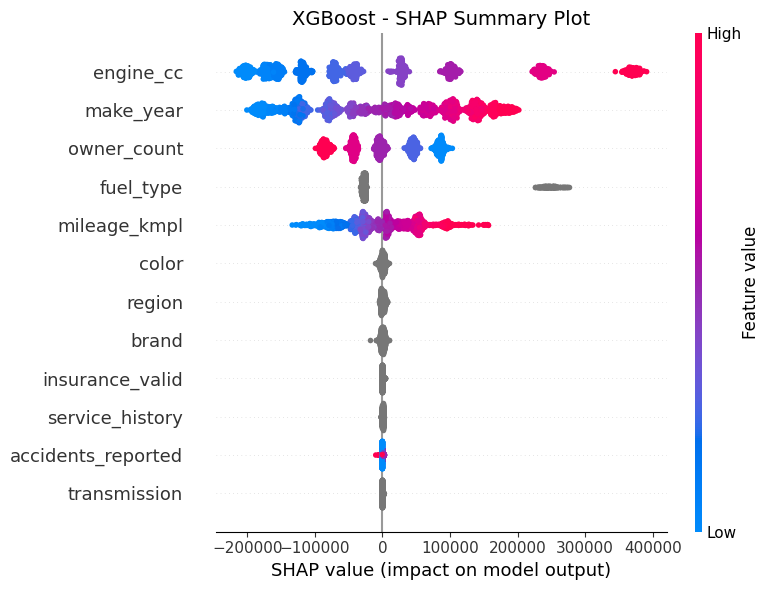

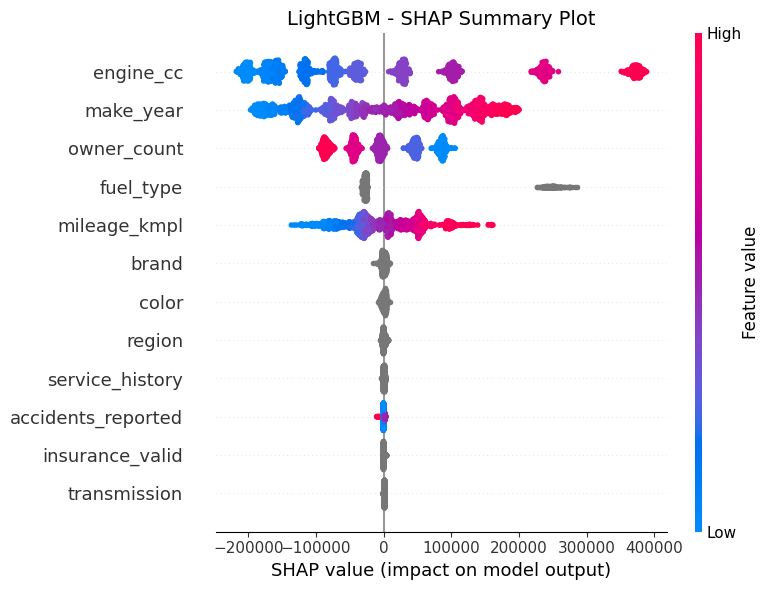

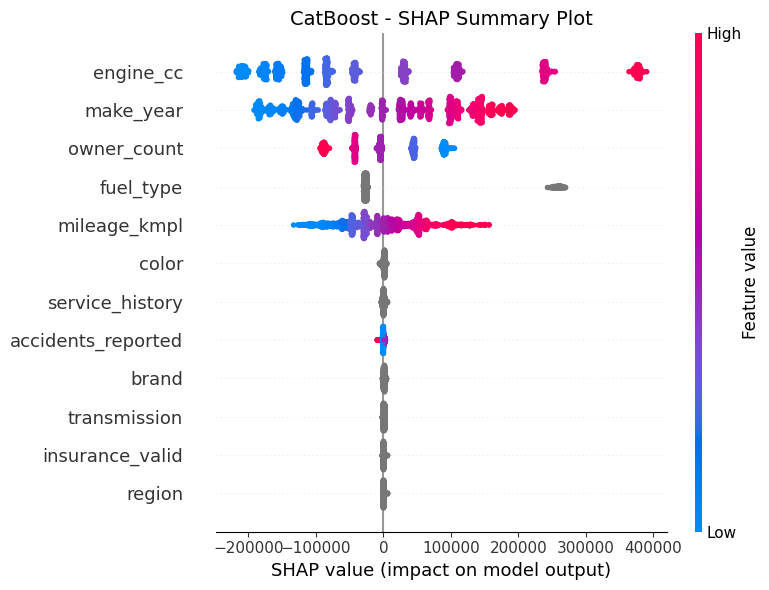

In [40]:
for name, model in models.items():
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(X_val)
    
    plt.figure(figsize=(8, 6))
    shap.summary_plot(
        shap_values, 
        X_val, 
        show=False,
        plot_size=None
    )
    
    plt.title(f'{name} - SHAP Summary Plot', fontsize=14)
    plt.tight_layout()
    plt.show()

#### Выводы
Графики практически идентичны у всех трёх моделей, что говорит о **согласованности выводов между библиотеками**.  


**Топ-5 признаков по вкладу в цену:**
- `engine_cc` - чем выше объем двигателя, тем выше цена;
- `make_year` - чем новее автомобиль, тем дороже;
- `owner_count` — много владельцев снижают цену, мало владельцев - увеличивают.
- `fuel_type` - оторванный кластер точек справа на уровне +250 000...+300 000 - это категория Electric:
    - у электромобилей средняя цена 928 тыс. руб. против ~656 тыс. у остальных;
    - модель абсолютно верно улавливает эту рыночную премию.
- `mileage_kmpl` - чем выше топливная эффективность транспортного средства, тем выше цена.

**Влияние `color` и `insurance_valid` на предсказание:**
- оба признака показывают SHAP-значения около нуля - модель не находит их существенного влияния на цену:
- соответствует бизнес-логике: цвет автомобиля и действующая страховка не должны определять рыночную стоимость самого авто.

---
### 9.2. Сравнение лучших моделей

In [41]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_val)
    row = evaluate(name, y_val, y_pred)
    
    results.append(row)

In [42]:
pd.DataFrame(results).style.format({
    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R2': '{:.3f}',
    'Overpricing Rate': '{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' ')
})

,Модель,RMSE,MAE,R2,Overpricing Rate,Underpricing Loss
0,XGBoost,100 711,80 182,0.850,13.38%,19 695 636
1,LightGBM,100 516,79 991,0.851,13.75%,17 595 653
2,CatBoost,98 878,79 167,0.856,13.19%,17 421 771


### Выводы
- **CatBoost** - лидирует по всем метрикам: разрыв с конкурентами после тюнинга сохранился.
- **XGBoost и LightGBM** подтянулись почти вплотную к **CatBoost** - тюнинг дал им больший прирост, чем CatBoost, что ожидаемо: baseline CatBoost изначально был ближе к оптимуму за счёт умной нативной обработки категорий.
- Все три модели «выбрали» неглубокие деревья (max_depth/depth = 3–4) с малым learning_rate и большим числом итераций — типичный паттерн для табличных данных среднего размера (6400 строк), где переобучение на глубоких деревьях — реальный риск.

---
### 9.3. Ошибки в разрезе категорий (марки автомобилей и макро-регионов)

- Собираем единый датафрейм: brand, region, y_true, прогнозы моделей

In [43]:
base_df = X_val[['brand', 'region']].copy()
base_df['y_true'] = y_val.values
 
for name, model in models.items():
    preds = model.predict(X_val)
    base_df[f'preds_{name}'] = preds
    base_df[f'error_ratio_{name}'] = (preds - y_val.values) / y_val.values
 
print(f'Датафрейм для анализа: {base_df.shape}')
base_df.head()

Датафрейм для анализа: (1600, 9)


,brand,region,y_true,preds_XGBoost,error_ratio_XGBoost,preds_LightGBM,error_ratio_LightGBM,preds_CatBoost,error_ratio_CatBoost
2215,Volkswagen,Дальний Восток,1141865,1.009942e+06,-0.115533,1.011628e+06,-0.114056,1.005022e+06,-0.119842
2582,Honda,Москва,663249,5.198591e+05,-0.216193,5.125409e+05,-0.227227,5.157895e+05,-0.222329
1662,Tesla,Дальний Восток,813337,9.101436e+05,0.119024,9.106328e+05,0.119625,9.141442e+05,0.123943
3027,Chevrolet,Урал,948732,9.154967e+05,-0.035031,9.269891e+05,-0.022918,9.098374e+05,-0.040996
4343,Kia,Дальний Восток,901438,7.763582e+05,-0.138756,7.826041e+05,-0.131827,7.819616e+05,-0.132540


- Реализуем функцию для расчёта бизнес-метрик по группе для каждой модели

In [44]:
def calc_by_group(group_col, df=base_df):
    rows = []
    
    for group_name, group in df.groupby(group_col, observed=True):
        row = {group_col: group_name, 'Кол-во': len(group)}
        for name in models:
            error_col = f'error_ratio_{name}'
            preds_col = f'preds_{name}'
        
            over_mask = group[error_col] > 0.20
            under_mask = group[error_col] < -0.20

            row[f'MAE_{name}'] = mean_absolute_error(group['y_true'], group[preds_col])
            row[f'Overpricing_Rate_{name}'] = over_mask.mean()
            row[f'Underpricing_Loss_{name}'] = (group.loc[under_mask, 'y_true'] - group.loc[under_mask, preds_col]).sum()

        rows.append(row)

    return rows

- Рассчитаем бизнес-метрики по маркам авто и регионам

In [45]:
brand_df = pd.DataFrame(calc_by_group('brand'))
region_df = pd.DataFrame(calc_by_group('region'))

mae_cols = ['MAE_CatBoost', 'MAE_LightGBM', 'MAE_XGBoost']
over_cols = ['Overpricing_Rate_CatBoost','Overpricing_Rate_LightGBM', 'Overpricing_Rate_XGBoost']
under_cols = ['Underpricing_Loss_CatBoost', 'Underpricing_Loss_LightGBM', 'Underpricing_Loss_XGBoost']

- Целевая метрика MAE в разрезе моделей

In [46]:
brand_df[['brand', 'Кол-во'] + mae_cols] \
    .sort_values(by=mae_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format(lambda x: f'{x:,.0f}'.replace(',', ' '), subset=mae_cols)

,brand,Кол-во,MAE_CatBoost,MAE_LightGBM,MAE_XGBoost
0,BMW,171,86 859,85 469,85 519
1,Toyota,152,85 866,85 976,84 827
2,Tesla,163,85 719,86 893,86 967
3,Kia,167,84 017,84 515,84 617
4,Ford,147,76 991,76 805,78 109
5,Hyundai,166,76 904,77 755,77 188
6,Volkswagen,173,76 432,76 813,78 150
7,Nissan,170,75 171,77 597,76 814
8,Chevrolet,159,71 185,72 943,74 032
9,Honda,132,70 874,73 858,74 417


- Целевая метрика MAE в разрезе регионов

In [47]:
region_df[['region', 'Кол-во'] + mae_cols] \
    .sort_values(by=mae_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format(lambda x: f'{x:,.0f}'.replace(',', ' '), subset=mae_cols)

,region,Кол-во,MAE_CatBoost,MAE_LightGBM,MAE_XGBoost
0,Урал,276,81 663,83 633,82 299
1,Сибирь,253,81 317,83 287,83 095
2,Дальний Восток,262,80 724,80 891,81 500
3,СПб,267,78 188,78 638,78 729
4,Юг,293,76 908,76 744,77 725
5,Москва,249,76 285,76 931,77 940


- Марки авто с высокой долей переплаты (Overpricing Rate)

In [48]:
brand_df[['brand'] + over_cols] \
    .sort_values(by=over_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format('{:.2%}', subset=over_cols)

,brand,Overpricing_Rate_CatBoost,Overpricing_Rate_LightGBM,Overpricing_Rate_XGBoost
0,Toyota,17.76%,19.08%,18.42%
1,Volkswagen,15.61%,17.92%,17.34%
2,Tesla,15.34%,15.95%,15.95%
3,Ford,14.29%,14.29%,12.93%
4,Hyundai,12.65%,12.05%,10.24%
5,Chevrolet,11.95%,12.58%,11.32%
6,Nissan,11.76%,11.76%,11.76%
7,Honda,11.36%,12.88%,14.39%
8,BMW,11.11%,11.11%,11.11%
9,Kia,10.18%,10.18%,10.78%


- Марки авто с высокой упущенной выгодой (Underpricing Loss)

In [49]:
brand_df[['brand'] + under_cols] \
    .sort_values(by=under_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format(lambda x: f'{x:,.0f}'.replace(',', ' '), subset=under_cols)

,brand,Underpricing_Loss_CatBoost,Underpricing_Loss_LightGBM,Underpricing_Loss_XGBoost
0,BMW,3 245 749,2 896 912,3 409 089
1,Volkswagen,1 979 616,1 846 303,2 320 695
2,Tesla,1 928 861,1 839 954,2 002 800
3,Kia,1 890 094,1 963 115,2 272 840
4,Toyota,1 831 994,2 091 023,2 264 815
5,Chevrolet,1 634 505,1 621 813,1 861 874
6,Nissan,1 609 792,2 051 753,2 085 207
7,Hyundai,1 542 017,1 634 282,1 509 022
8,Ford,1 216 602,873 079,1 080 216
9,Honda,542 540,777 420,889 078


- Регионы с высокой долей переплаты (Overpricing Rate):

In [50]:
region_df[['region'] + over_cols] \
    .sort_values(by=over_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format('{:.2%}', subset=over_cols)

,region,Overpricing_Rate_CatBoost,Overpricing_Rate_LightGBM,Overpricing_Rate_XGBoost
0,Урал,15.94%,15.58%,15.22%
1,Сибирь,15.81%,15.81%,15.02%
2,Юг,13.99%,14.68%,15.02%
3,СПб,12.73%,13.86%,13.11%
4,Москва,12.45%,12.45%,12.45%
5,Дальний Восток,8.02%,9.92%,9.16%


- Регионы с высокой упущенной выгодой (Underpricing Loss):

In [51]:
region_df[['region'] + under_cols] \
    .sort_values(by=under_cols, ascending=False) \
    .reset_index(drop=True) \
    .style.format(lambda x: f'{x:,.0f}'.replace(',', ' '), subset=under_cols)

,region,Underpricing_Loss_CatBoost,Underpricing_Loss_LightGBM,Underpricing_Loss_XGBoost
0,СПб,3 927 246,3 796 058,3 691 162
1,Юг,3 409 188,3 119 684,3 541 948
2,Дальний Восток,3 158 986,3 231 658,4 171 895
3,Москва,2 623 198,2 712 175,3 347 277
4,Сибирь,2 201 010,2 355 601,2 619 332
5,Урал,2 102 143,2 380 477,2 324 022


### Выводы
**По маркам**
- **МАЕ**:
    - самая **большая** ошибка: **BMW, Toyota, Tesla** (85 - 87 тыс. руб);
    - самая **низкая** ошибка: **Chevrolet, Honda** (71 - 74 тыс.руб).
- **Overpricing Rate**:
    - **высокая** доля переплаты: **Toyota, Volkswagen, Tesla** (15–19%);
    - **низкая** доля переплаты: **BMW, Kia** (10-11%);
- **Underpricing Loss**:
    - самая **большая** упущенная выгода: **BMW** (2.9–3.4 млн. руб);
    - самая **низкая** упущенная выгода: **Honda** (0.5–0.9 млн. руб).

**По регионам**
- **МАЕ**:
    - самая **большая** ошибка: **Урал, Сибирь** (81 - 84 тыс. руб);
    - самая **низкая** ошибка: **Москва, Юг** (76 - 78 тыс.руб).
- **Overpricing Rate**:
    - **высокая** доля переплаты: **Урал, Сибирь** (15–16%);
    - **низкая** доля переплаты: **Дальний Восток** (8-10%);
- **Underpricing Loss**:
    - самая **большая** упущенная выгода: **СПб** (3.7–3.9 млн. руб);
    - самая **низкая** упущенная выгода: **Урал** (2.1–2.4 млн. руб).

---
## 10. Финальная модель <a id='final'></a>

In [52]:
final_model = models['CatBoost']
final_model_params = best_params_catboost

In [53]:
summary = {
    'Model': 'CatBoost',
    **final_model_params
}

pd.Series(summary, name='Final Model Config').to_frame()

,Final Model Config
Model,CatBoost
learning_rate,0.06799
depth,4
iterations,772
l2_leaf_reg,2.650641


- Получим предсказания финальной модели на валидационной и тестовой выборках

In [54]:
results = []

y_pred = final_model.predict(X_val)    
row = evaluate('CatBoost', y_val, y_pred)
results.append(row)

y_pred = final_model.predict(X_test)    
row = evaluate('CatBoost', y_test, y_pred)   
results.append(row)

In [55]:
pd.DataFrame(results, index=['val', 'test']).style.format({
    'RMSE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'MAE': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'R2': '{:.3f}',
    'Overpricing Rate': '{:.2%}',
    'Underpricing Loss': lambda x: f'{x:,.0f}'.replace(',', ' '),
    'Время обучения': '{:.3f}',
    'Время предсказания':  '{:.3f}'
})

,Модель,RMSE,MAE,R2,Overpricing Rate,Underpricing Loss
val,CatBoost,98 878,79 167,0.856,13.19%,17 421 771
test,CatBoost,95 047,75 777,0.874,13.40%,20 058 514


- Сохраним финальную модель

In [56]:
joblib.dump(final_model, 'models/final_model.joblib')

['models/final_model.joblib']

- Проверим работоспособность

In [57]:
model_prod = joblib.load('models/final_model.joblib')

y_pred = final_model.predict(X_test)
y_pred_prod = model_prod.predict(X_test)

equality = np.all(y_pred == y_pred_prod)

print("Прогнозы модели совпадают:", equality)

Прогнозы модели совпадают: True


### Выводы
**Результаты финальной модели на тестовой выборке:**
- **RMSE** - 95 047;
- **MAE** - 75 777;
- **R2** - 0.874;
- **Overpricing Rate** - 13.40%;
- **Underpricing Loss** - 20 058 514.

**Признаков существенного переобучения не обнаружено:**
- Метрики регрессии на test лучше, чем на validation:
    - **RMSE**: 95 047 против 98 878;
    - **MAE**: 75 777 против 79 167;
    - **R2**: 0.874 против 0.856.
- **Overpricing Rate** стабилен: 13.40% на test против 13.19% на validation — модель одинаково ведёт себя с точки зрения бизнес-риска независимо от конкретных данных.
- **Underpricing Loss**: на тесте 20.1 млн руб. на 2000 машин против 17.4 млн руб. на 1600 машин на валидации:
    - в пересчёте на одну машину это ~10 000 руб./машину на test против ~10 900 руб./машину на val.

**Итоговая рекомендация**
- **Модель CatBoost готова к промышленной эксплуатации** - её метрики на полностью незнакомых данных (`ds_s16_test_data.csv`) соответствуют ожиданиям, сформированным на этапах обучения и валидации, без признаков переобучения под конкретную обучающую выборку.


## 11. Аналитическая записка по проекту AutoValue AI <a id='resume'></a>

1. **Рекомендованная модель:** CatBoost (с оптимизированными через Optuna гиперпараметрами), победитель турнира трёх библиотек градиентного бустинга (LightGBM, XGBoost, CatBoost).

2. **Точность оценки:** на отложенной тестовой выборке (2000 сделок, не участвовавших ни в обучении, ни в подборе гиперпараметров) **модель в среднем ошибается на 75 777 руб (MAE)**. Коэффициент детерминации составляет **R2 = 0.874**, что подтверждает высокую надёжность прогнозов — модель объясняет более 87% вариации рыночной цены автомобиля на основе имеющихся признаков.

3. **Безопасность бюджета:** риск опасной переплаты (**Overpricing Rate**, прогноз выше реальной цены более чем на 20%) зафиксирован на уровне **13.4% сделок**. Это позволяет компании сохранять маржинальность при выкупе — из 2000 машин тестовой выборки лишь 268 попали в зону риска переплаты, что соответствует показателям, полученным на валидации (13.19%), то есть риск стабилен и предсказуем.

4. **Упущенная выгода:** на тестовой выборке зафиксирована суммарная упущенная выгода (**Underpricing Loss**) в размере 20 058 514 руб на 2000 сделок — то есть в среднем около 10 029 руб на одну машину. **Наибольший риск крупной недооценки** сосредоточен в премиум-сегменте (**марка BMW: 3.2 млн руб. на валидации**) - рекомендуется ручной пересмотр цены для премиум-сегмента перед автоматическим одобрением сделки.

5. **Зоны риска: модель наиболее нестабильна:**

- **по регионам** - **Урал и Сибирь** (повышенный Overpricing Rate, ~16%), а также **Санкт-Петербург** (наибольшая упущенная выгода Underpricing Loss - 3.9 млн руб);
- **по маркам** - **Toyota и Volkswagen** (повышенный риск переплаты, 16–18%), **BMW** (наибольший риск крупной недооценки в премиум-сегменте - 3.2 млн руб).

6. **Гиперпараметры для фиксации при интеграции в мобильное приложение:**

- `loss_function`: MAE;
- `learning_rate`: 0.067990;
- `depth`: 4;
- `iterations`: 772;
- `l2_leaf_reg`: 2.650641;
- `early_stopping_rounds`: 50 (с `use_best_model=True`);
- `random_state`: 42;
- `cat_features`: brand, fuel_type, transmission, color, service_history, insurance_valid, region.
